<a href="https://colab.research.google.com/github/nmemranhussain/cardio-triage-4-agents/blob/main/notebooks%20/%2002_acat_advanced_lgbm_calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os

# 1. Securely fetch your PAT and clone your repository to get the data folder
PAT = userdata.get('GITHUB_PAT')
USERNAME = "nmemranhussain"
REPO = "cardio-triage-4-agents"

if not os.path.exists(REPO):
    !git clone https://{PAT}@github.com/{USERNAME}/{REPO}.git

# 2. Change into the repository directory
%cd cardio-triage-4-agents
!pwd

Cloning into 'cardio-triage-4-agents'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 23 (delta 7), reused 8 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 6.67 MiB | 15.99 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/cardio-triage-4-agents
/content/cardio-triage-4-agents


**Implementing LightGBM & Calibration**

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import precision_recall_curve, auc, brier_score_loss
import lightgbm as lgb

print("Loading dataset...")
df = pd.read_csv('data/sample_condition_occurrence.csv')
df['condition_start_date'] = pd.to_datetime(df['condition_start_date'])

# 1. Temporal Feature Engineering (same rigorous setup as baseline)
print("Setting up temporal observation and prediction windows...")
patient_first_last = df.groupby('person_id')['condition_start_date'].agg(['min', 'max']).reset_index()
patient_first_last['median_date'] = patient_first_last['min'] + (patient_first_last['max'] - patient_first_last['min']) / 2
df = df.merge(patient_first_last[['person_id', 'median_date']], on='person_id', how='left')

obs_df = df[df['condition_start_date'] <= df['median_date']]
X_features = obs_df.groupby('person_id').agg(
    hist_distinct_conditions=('condition_concept_id', 'nunique'),
    hist_total_conditions=('condition_concept_id', 'count')
).reset_index()

pred_df = df[df['condition_start_date'] > df['median_date']]
y_target = pred_df.groupby('person_id').size().reset_index(name='future_conditions')

model_df = X_features.merge(y_target, on='person_id', how='inner')
utilization_threshold = model_df['future_conditions'].quantile(0.75)
model_df['target'] = (model_df['future_conditions'] > utilization_threshold).astype(int)

X = model_df[['hist_distinct_conditions', 'hist_total_conditions']]
y = model_df['target']
groups = model_df['person_id']

# 2. Patient-Level Split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 3. Train LightGBM Model
print("Training Advanced LightGBM model...")
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

# 4. Evaluation
y_pred_proba = lgb_model.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)
brier = brier_score_loss(y_test, y_pred_proba)

print("\n--- LightGBM Advanced Model Results ---")
print(f"PR-AUC: {pr_auc:.4f}")
print(f"Brier Score (Calibration): {brier:.4f}")

Loading dataset...
Setting up temporal observation and prediction windows...
Training Advanced LightGBM model...

--- LightGBM Advanced Model Results ---
PR-AUC: 0.2342
Brier Score (Calibration): 0.2448


**Random Forest**

In [4]:
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest model for comparison
print("Training Random Forest model...")
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate Random Forest
rf_proba = rf_model.predict_proba(X_test)[:, 1]
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_proba)
rf_pr_auc = auc(rf_recall, rf_precision)
rf_brier = brier_score_loss(y_test, rf_proba)

print(f"\nRandom Forest -> PR-AUC: {rf_pr_auc:.4f} | Brier Score: {rf_brier:.4f}")

Training Random Forest model...

Random Forest -> PR-AUC: 0.2340 | Brier Score: 0.2449


**Run the Enhanced Feature Engineering & SHAP Script**

Generating SHAP feature importance for clinical interpretability...


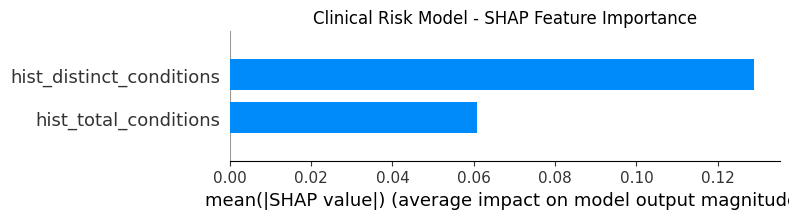

SHAP summary plot successfully saved to evaluation/shap_summary_bar.png!


In [5]:
import shap
import matplotlib.pyplot as plt
import os

print("Generating SHAP feature importance for clinical interpretability...")

# Use the trained LightGBM model for SHAP calculation
explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer(X_test)

# Ensure evaluation directory exists
os.makedirs('evaluation', exist_ok=True)

# Plot and save the feature importance summary
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("Clinical Risk Model - SHAP Feature Importance")
plt.tight_layout()

# Save figure to evaluation folder
eval_path = 'evaluation/shap_summary_bar.png'
plt.savefig(eval_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"SHAP summary plot successfully saved to {eval_path}!")

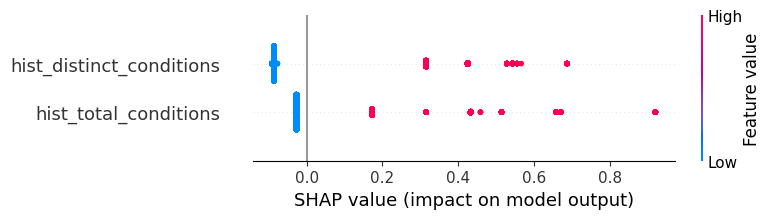

<Figure size 640x480 with 0 Axes>

In [6]:
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test) # Leaves out plot_type="bar" for the full beeswarm view
plt.tight_layout()
plt.show()